# Proyecto EDA paso a paso

**Módulo 8 · Python for Data**

Este notebook analiza las campañas telefónicas y su relación con las fichas de clientes. Ejecuta las celdas en orden. Se emplean Python, Pandas y Matplotlib. Los datos originales están en `data/raw/`.


## Preparación opcional: instalar las bibliotecas

Si Pandas o Matplotlib no están disponibles en el kernel seleccionado, ejecuta esta celda una vez. Si ya están instaladas, puedes continuar.


In [1]:
%pip install pandas matplotlib


Pandas y Matplotlib ya están disponibles; no es necesario instalar nada.


## 1. Importar Pandas y localizar la carpeta del proyecto

Si VS Code inicia el notebook desde `notebooks`, esta celda pasa a la carpeta principal para encontrar `data` y `outputs`.


In [2]:
import os
import pandas as pd

ROOT = os.getcwd()
if "data" not in os.listdir(ROOT):
    os.chdir("..")
    ROOT = os.getcwd()

RAW = os.path.join(ROOT, "data", "raw")
INPUT = os.path.join(ROOT, "data", "input")
PROCESSED = os.path.join(ROOT, "data", "processed")
CHARTS = os.path.join(ROOT, "outputs", "graficos")
print("Carpeta del proyecto:", ROOT)


Carpeta del proyecto: C:\Users\TPV SYSTEM\Desktop\EDA CURSO\PYTHON FOR DATA


## 2. Cargar y explorar las campañas

Comprueba las primeras filas, el tamaño, los nombres de columnas y los tipos de datos.

In [3]:
campaigns_raw = pd.read_csv(os.path.join(RAW, "bank-additional.csv"))

print("Tamaño:", campaigns_raw.shape)
campaigns_raw.head()


Tamaño: (43000, 24)


   Unnamed: 0   age        job  marital    education  default  housing  ...  euribor3m nr.employed   y                date  latitude  longitude                                   id_
0           0   NaN  housemaid  MARRIED     basic.4y      0.0      0.0  ...      4,857        5191  no       2-agosto-2019    41.495    -71.233  089b39d8-e4d0-461b-87d4-814d71e0e079
1           1  57.0   services  MARRIED  high.school      NaN      0.0  ...        NaN        5191  no  14-septiembre-2016    34.601    -83.923  e9d37224-cb6f-4942-98d7-46672963d097
2           2  37.0   services  MARRIED  high.school      0.0      1.0  ...      4,857        5191  no     15-febrero-2019    34.939    -94.847  3f9f49b5-e410-4948-bf6e-f9244f04918b
3           3  40.0     admin.  MARRIED     basic.6y      0.0      0.0  ...        NaN        5191  no   29-noviembre-2015    49.041    -70.308  9991fafb-4447-451a-8be2-b0df6098d13e
4           4  56.0   services  MARRIED  high.school      0.0      0.0  ...        NaN    

In [4]:
campaigns_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      43000 non-null  int64  
 1   age             37880 non-null  float64
 2   job             42655 non-null  str    
 3   marital         42915 non-null  str    
 4   education       41193 non-null  str    
 5   default         34019 non-null  float64
 6   housing         41974 non-null  float64
 7   loan            41974 non-null  float64
 8   contact         43000 non-null  str    
 9   duration        43000 non-null  int64  
 10  campaign        43000 non-null  int64  
 11  pdays           43000 non-null  int64  
 12  previous        43000 non-null  int64  
 13  poutcome        43000 non-null  str    
 14  emp.var.rate    43000 non-null  float64
 15  cons.price.idx  42529 non-null  str    
 16  cons.conf.idx   43000 non-null  str    
 17  euribor3m       33744 non-null  str    
 1

## 3. Revisar valores ausentes y duplicados

Esta revisión ayuda a decidir qué limpiar. Los ausentes de edad y de variables económicas se conservarán y se describirá su alcance; no se imputan valores inventados.


In [5]:
campaigns_raw.isnull().sum()


Unnamed: 0           0
age               5120
job                345
marital             85
education         1807
default           8981
housing           1026
loan              1026
contact              0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx     471
cons.conf.idx        0
euribor3m         9256
nr.employed          0
y                    0
date               248
latitude             0
longitude            0
id_                  0

In [6]:
print("Filas duplicadas:", campaigns_raw.duplicated().sum())
print("Identificadores id_ duplicados:", campaigns_raw["id_"].duplicated().sum())


Filas duplicadas: 0
Identificadores id_ duplicados: 0


## 4. Limpiar las campañas

Se quita la columna de índice exportada y se convierten las cuatro columnas con coma decimal. Se conserva `age` con sus ausentes.


In [7]:
campaigns = campaigns_raw.copy()

unnamed_columns = []
for column in campaigns.columns:
    if "Unnamed:" in column:
        unnamed_columns.append(column)

campaigns = campaigns.drop(unnamed_columns, axis=1)

decimal_columns = ["cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
for column in decimal_columns:
    campaigns[column] = campaigns[column].str.replace(",", ".").astype(float)

# Los nombres de los meses vienen en español; se traducen para convertir la fecha.
month_translation = {
    "enero": "January", "febrero": "February", "marzo": "March",
    "abril": "April", "mayo": "May", "junio": "June",
    "julio": "July", "agosto": "August", "septiembre": "September",
    "octubre": "October", "noviembre": "November", "diciembre": "December"
}
date_parts = campaigns["date"].str.split("-")
english_dates = date_parts.str[0] + "-" + date_parts.str[1].str.lower().replace(month_translation) + "-" + date_parts.str[2]
campaigns["date"] = pd.to_datetime(english_dates, format="%d-%B-%Y", errors="coerce")
campaigns["contact_month"] = campaigns["date"].dt.month
campaigns["contact_year"] = campaigns["date"].dt.year

print("Tamaño después de quitar el índice:", campaigns.shape)
print("Fechas no convertidas o ausentes:", campaigns["date"].isnull().sum())
campaigns.head()


Tamaño después de quitar el índice: (43000, 25)
Fechas no convertidas o ausentes: 248


    age        job  marital    education  default  housing  loan  ...   y       date  latitude  longitude                                   id_ contact_month  contact_year
0   NaN  housemaid  MARRIED     basic.4y      0.0      0.0   0.0  ...  no 2019-08-02    41.495    -71.233  089b39d8-e4d0-461b-87d4-814d71e0e079           8.0        2019.0
1  57.0   services  MARRIED  high.school      NaN      0.0   0.0  ...  no 2016-09-14    34.601    -83.923  e9d37224-cb6f-4942-98d7-46672963d097           9.0        2016.0
2  37.0   services  MARRIED  high.school      0.0      1.0   0.0  ...  no 2019-02-15    34.939    -94.847  3f9f49b5-e410-4948-bf6e-f9244f04918b           2.0        2019.0
3  40.0     admin.  MARRIED     basic.6y      0.0      0.0   0.0  ...  no 2015-11-29    49.041    -70.308  9991fafb-4447-451a-8be2-b0df6098d13e          11.0        2015.0
4  56.0   services  MARRIED  high.school      0.0      0.0   1.0  ...  no 2017-01-29    38.033   -104.463  eca60b76-70b6-4077-80ba-bc52e8ebb

## 5. Unir las tres hojas de clientes

Primero se intenta leer el Excel original con `sheet_name=None`, que carga sus hojas en un diccionario. Se apilan las hojas con `pd.concat` y se conserva el año de cada hoja. La lectura de Excel con Pandas puede requerir que el entorno ya tenga instalado el motor que usa `read_excel` (normalmente `openpyxl`). Si no está disponible, el bloque usa el CSV combinado incluido en `data/input/`, que se generó a partir de esas hojas.


In [8]:
customer_path = os.path.join(RAW, "customer-details.xlsx")
input_path = os.path.join(INPUT, "customer-details-combinado.csv")

try:
    customer_sheets = pd.read_excel(customer_path, sheet_name=None)
    customer_frames = []
    for sheet_name, sheet_data in customer_sheets.items():
        unnamed_columns = []
        for column in sheet_data.columns:
            if "Unnamed:" in column:
                unnamed_columns.append(column)
        sheet_data = sheet_data.drop(unnamed_columns, axis=1)
        sheet_data["customer_sheet_year"] = sheet_name
        customer_frames.append(sheet_data)
    customers = pd.concat(customer_frames, ignore_index=True)
    print("Fichas cargadas desde las hojas del Excel:", list(customer_sheets.keys()))
except ImportError as error:
    if "openpyxl" not in str(error).lower():
        raise
    print("No está disponible el lector Excel del entorno; se utilizará el CSV combinado de entrada.")
    customers = pd.read_csv(input_path)

print("Fichas de clientes:", customers.shape)
print("IDs duplicados:", customers["ID"].duplicated().sum())
customers.head()


Fichas cargadas desde las hojas del Excel: ['2012', '2013', '2014']
Fichas de clientes: (43170, 7)
IDs duplicados: 0


   Income  Kidhome  Teenhome Dt_Customer  NumWebVisitsMonth                                    ID customer_sheet_year
0  161770        1         0  2012-04-04                 29  089b39d8-e4d0-461b-87d4-814d71e0e079                2012
1   85477        1         1  2012-12-30                  7  e9d37224-cb6f-4942-98d7-46672963d097                2012
2  147233        1         1  2012-02-02                  5  3f9f49b5-e410-4948-bf6e-f9244f04918b                2012
3  121393        1         2  2012-12-21                 29  9991fafb-4447-451a-8be2-b0df6098d13e                2012
4   63164        1         2  2012-06-20                 20  eca60b76-70b6-4077-80ba-bc52e8ebb0eb                2012

## 6. Combinar campañas y clientes

Se usa un cruce `left` por `id_` y `ID`. Se mantienen todas las campañas y se comprueba cuántas encontraron ficha.


In [9]:
merged = campaigns.merge(
    customers, how="left", left_on="id_", right_on="ID"
)
combined = merged.drop(["ID"], axis=1)

print("Campañas:", len(campaigns))
print("Fichas combinadas:", len(customers))
print("Campañas con ficha enlazada:", combined["Income"].count())
print("Tamaño del cruce:", combined.shape)


Campañas: 43000
Fichas combinadas: 43170
Campañas con ficha enlazada: 43000
Tamaño del cruce: (43000, 31)


## 7. Analizar el resultado general

`y` indica si hubo suscripción. Se revisan los conteos y la tasa sobre el total.


In [10]:
target_counts = campaigns["y"].value_counts()
target_counts


y
no     38156
yes     4844

In [11]:
subscription_rate = target_counts["yes"] / len(campaigns)
print("Tasa de suscripción:", f"{subscription_rate:.2%}")


Tasa de suscripción: 11.27%


## 8. Comparar la tasa por canal

Se agrupan los registros por canal y se cuentan los contactos y las suscripciones.

In [12]:
channel_summary = campaigns.groupby("contact")["y"].agg(
    ["count", lambda values: (values == "yes").sum()]
)
channel_summary.columns = ["contacts", "subscriptions"]
channel_summary["rate"] = channel_summary["subscriptions"] / channel_summary["contacts"]
channel_summary


           contacts  subscriptions      rate
contact                                     
cellular      27396           4039  0.147430
telephone     15604            805  0.051589

## 9. Comparar según el resultado de la campaña anterior

In [13]:
previous_summary = campaigns.groupby("poutcome")["y"].agg(
    ["count", lambda values: (values == "yes").sum()]
)
previous_summary.columns = ["contacts", "subscriptions"]
previous_summary["rate"] = previous_summary["subscriptions"] / previous_summary["contacts"]
previous_summary


             contacts  subscriptions      rate
poutcome                                      
FAILURE          4461            635  0.142345
NONEXISTENT     37103           3271  0.088160
SUCCESS          1436            938  0.653203

## 10. Revisar duración, ingresos y visitas web

Son resúmenes descriptivos por resultado; no prueban que estas variables causen la suscripción.


In [14]:
duration_summary = combined.groupby("y")["duration"].agg(["mean", "median"])
duration_summary


           mean  median
y                      
no   220.430208   163.0
yes  551.621387   449.0

In [15]:
income_summary = combined.groupby("y")["Income"].agg(["mean", "median"])
income_summary


             mean   median
y                         
no   93324.595031  93206.5
yes  92584.301197  92144.5

In [16]:
visits_summary = combined.groupby("y")["NumWebVisitsMonth"].agg(["mean", "median"])
visits_summary


          mean  median
y                     
no   16.587850    17.0
yes  16.604253    17.0

In [17]:
# Revisar los ausentes de edad y euribor3m sin imputarlos
missing_summary = campaigns[["age", "euribor3m"]].isnull().sum()
missing_summary


age          5120
euribor3m    9256

In [18]:
import matplotlib.pyplot as plt


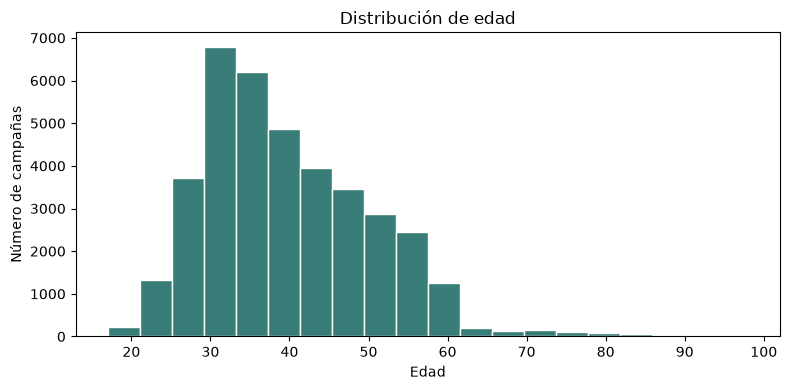

In [19]:
# Histograma de edad: ignora automáticamente los valores ausentes
plt.figure(figsize=(8, 4))
plt.hist(campaigns["age"].dropna(), bins=20, color="#397d78", edgecolor="white")
plt.title("Distribución de edad")
plt.xlabel("Edad")
plt.ylabel("Número de campañas")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "05_distribucion_edad.png"))
plt.show()


## 11. Resultados principales de campaña

Se muestran primero los resultados generales y las comparaciones por canal, resultado anterior y duración. Después se amplía el EDA con distribuciones y relaciones entre variables.


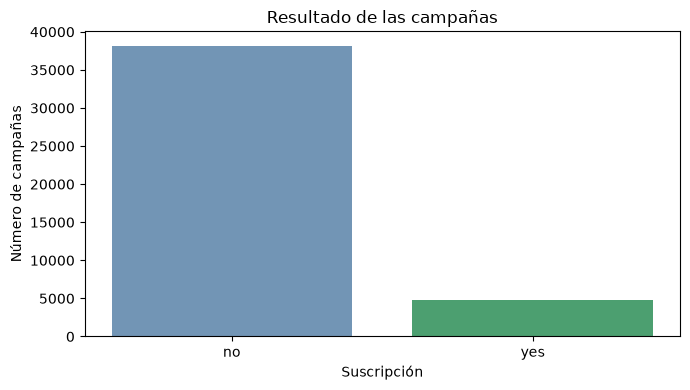

In [20]:
plt.figure(figsize=(7, 4))
plt.bar(target_counts.index, target_counts.values, color=["#7295b5", "#4c9f70"])
plt.title("Resultado de las campañas")
plt.xlabel("Suscripción")
plt.ylabel("Número de campañas")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "01_resultado_campana.png"))
plt.show()


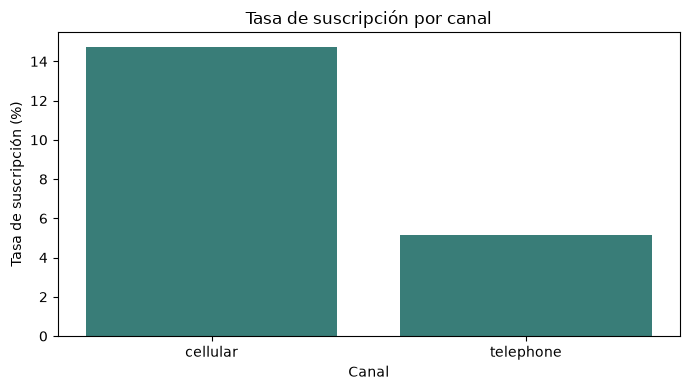

In [21]:
plt.figure(figsize=(7, 4))
plt.bar(channel_summary.index, channel_summary["rate"] * 100, color="#397d78")
plt.title("Tasa de suscripción por canal")
plt.xlabel("Canal")
plt.ylabel("Tasa de suscripción (%)")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "02_tasa_por_canal.png"))
plt.show()


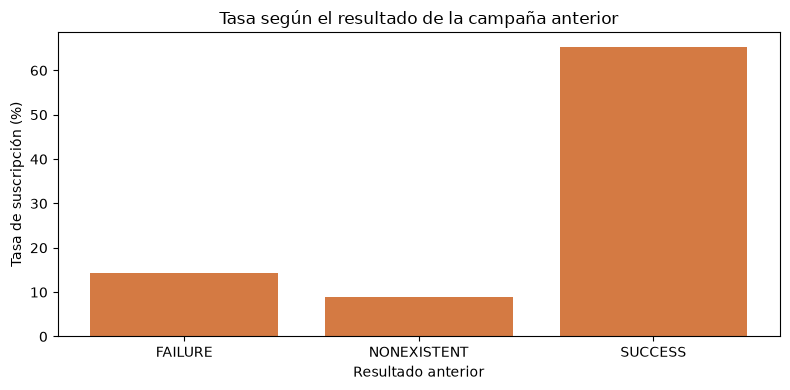

In [22]:
plt.figure(figsize=(8, 4))
plt.bar(previous_summary.index, previous_summary["rate"] * 100, color="#d47a43")
plt.title("Tasa según el resultado de la campaña anterior")
plt.xlabel("Resultado anterior")
plt.ylabel("Tasa de suscripción (%)")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "03_tasa_resultado_previo.png"))
plt.show()


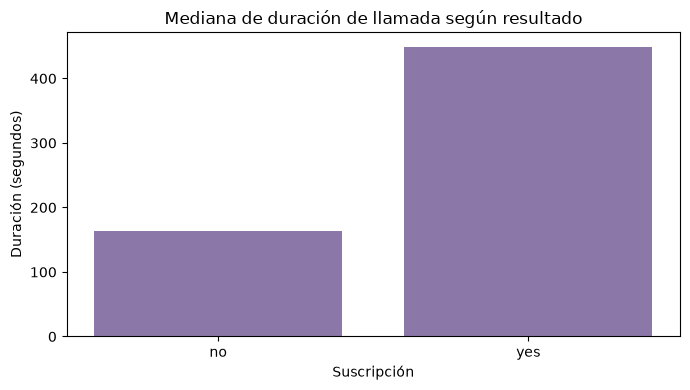

In [23]:
plt.figure(figsize=(7, 4))
plt.bar(duration_summary.index, duration_summary["median"], color="#8c78a8")
plt.title("Mediana de duración de llamada según resultado")
plt.xlabel("Suscripción")
plt.ylabel("Duración (segundos)")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "04_mediana_duracion.png"))
plt.show()


## 12. Distribuciones, valores atípicos y correlaciones

Los histogramas ayudan a observar la forma de las distribuciones; los diagramas de caja permiten localizar valores alejados. La correlación describe relaciones lineales entre variables numéricas y no implica causalidad. Para evitar distorsiones, cada cálculo usa los valores disponibles de esa variable.


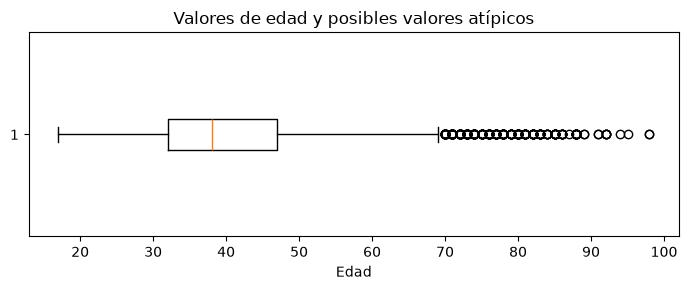

In [24]:
# Diagrama de caja para observar edades alejadas del centro de la distribución
plt.figure(figsize=(7, 3))
plt.boxplot(campaigns["age"].dropna(), vert=False)
plt.title("Valores de edad y posibles valores atípicos")
plt.xlabel("Edad")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "06_caja_edad.png"))
plt.show()


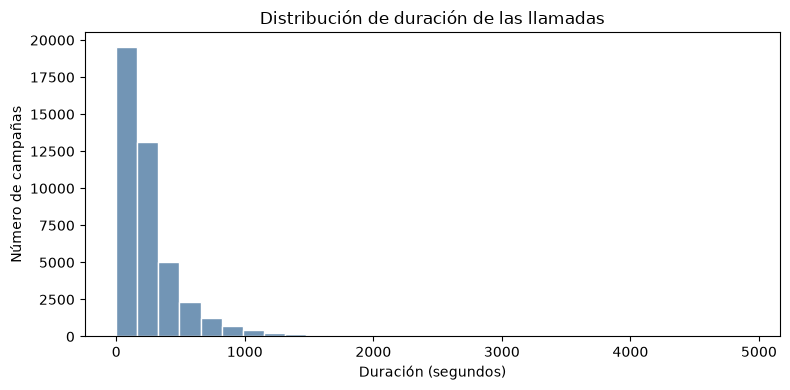

In [25]:
# Histograma de duración; la cola larga puede hacer que los valores altos se vean comprimidos
plt.figure(figsize=(8, 4))
plt.hist(campaigns["duration"], bins=30, color="#7295b5", edgecolor="white")
plt.title("Distribución de duración de las llamadas")
plt.xlabel("Duración (segundos)")
plt.ylabel("Número de campañas")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "07_distribucion_duracion.png"))
plt.show()


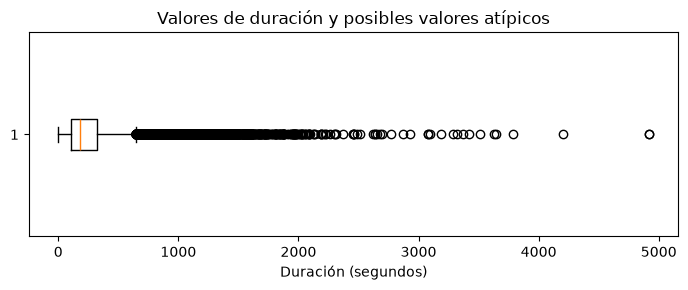

In [26]:
plt.figure(figsize=(7, 3))
plt.boxplot(campaigns["duration"], vert=False)
plt.title("Valores de duración y posibles valores atípicos")
plt.xlabel("Duración (segundos)")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "08_caja_duracion.png"))
plt.show()


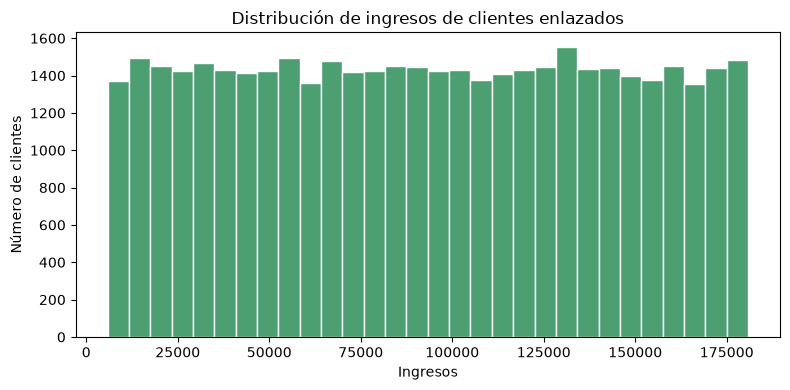

In [27]:
# Histograma de ingresos usando las fichas enlazadas
plt.figure(figsize=(8, 4))
plt.hist(combined["Income"].dropna(), bins=30, color="#4c9f70", edgecolor="white")
plt.title("Distribución de ingresos de clientes enlazados")
plt.xlabel("Ingresos")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "09_distribucion_ingresos.png"))
plt.show()


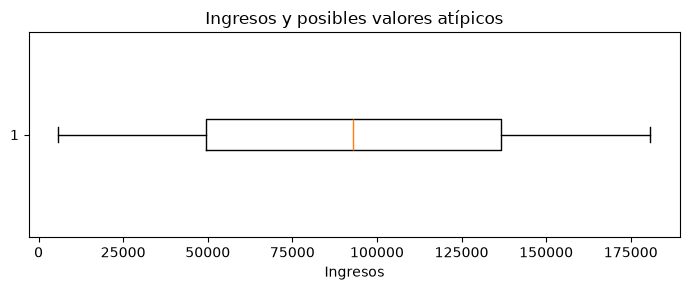

In [28]:
plt.figure(figsize=(7, 3))
plt.boxplot(combined["Income"].dropna(), vert=False)
plt.title("Ingresos y posibles valores atípicos")
plt.xlabel("Ingresos")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "10_caja_ingresos.png"))
plt.show()


In [29]:
# Correlación entre variables numéricas de campaña y cliente
numeric_columns = ["age", "duration", "campaign", "previous", "emp.var.rate",
                   "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed",
                   "Income", "Kidhome", "Teenhome", "NumWebVisitsMonth"]
correlation = combined[numeric_columns].corr()
correlation


                        age  duration  campaign  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed    Income   Kidhome  Teenhome  NumWebVisitsMonth
age                1.000000 -0.000073  0.005374  0.024399     -0.002948       -0.000586       0.128299   0.010250    -0.019235  0.001463  0.000987 -0.001046          -0.003767
duration          -0.000073  1.000000 -0.071956  0.021285     -0.027158        0.005854      -0.007631  -0.034426    -0.044157 -0.002761 -0.000759 -0.005937           0.000750
campaign           0.005374 -0.071956  1.000000 -0.079603      0.152084        0.128895      -0.012867   0.137343     0.145089 -0.003736 -0.006733  0.000802           0.004470
previous           0.024399  0.021285 -0.079603  1.000000     -0.419110       -0.200664      -0.048914  -0.459629    -0.501641 -0.003207 -0.000851 -0.003012          -0.001967
emp.var.rate      -0.002948 -0.027158  0.152084 -0.419110      1.000000        0.775699       0.192004   0.972361     0.

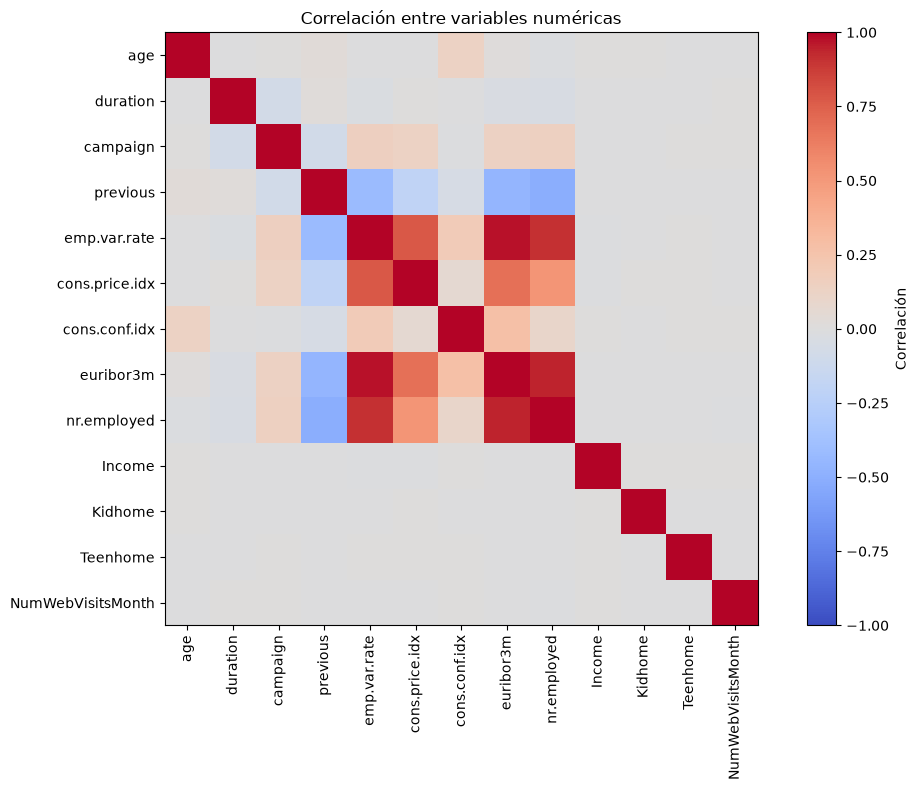

In [30]:
plt.figure(figsize=(11, 8))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlación")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.index)), correlation.index)
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "11_correlaciones.png"))
plt.show()


## 13. Análisis temporal por mes y año

La fecha original incluye día, mes en español y año. Tras traducir el nombre del mes, se convirtió a fecha y se extrajeron el mes y el año para resumir las tasas en el tiempo. Las fechas ausentes se mantienen y no entran en estos resúmenes.


In [31]:
month_names = ["enero", "febrero", "marzo", "abril", "mayo", "junio",
               "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]
monthly_summary = campaigns.groupby("contact_month")["y"].agg(
    ["count", lambda values: (values == "yes").sum()]
)
monthly_summary.columns = ["contacts", "subscriptions"]
monthly_summary["rate"] = monthly_summary["subscriptions"] / monthly_summary["contacts"]
monthly_summary.index = [month_names[int(month) - 1] for month in monthly_summary.index]
monthly_summary


            contacts  subscriptions      rate
enero           3517            408  0.116008
febrero         3577            398  0.111266
marzo           3589            385  0.107272
abril           3582            401  0.111949
mayo            3547            377  0.106287
junio           3538            401  0.113341
julio           3593            410  0.114111
agosto          3526            404  0.114577
septiembre      3569            366  0.102550
octubre         3599            445  0.123645
noviembre       3603            414  0.114904
diciembre       3512            402  0.114465

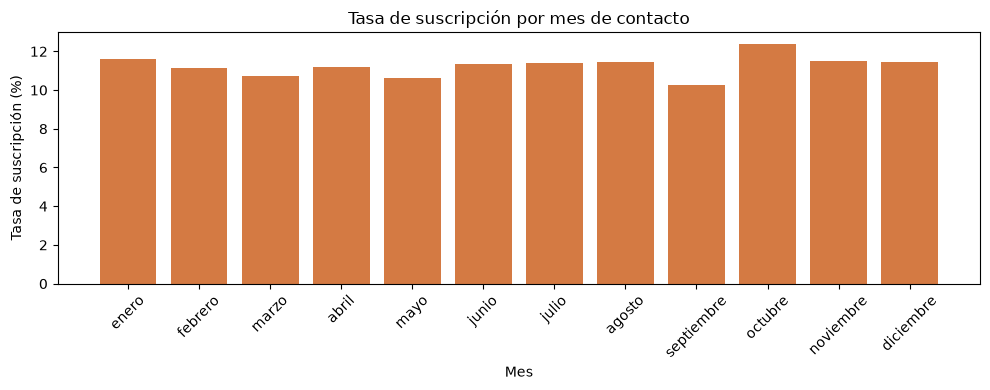

In [32]:
plt.figure(figsize=(10, 4))
plt.bar(monthly_summary.index, monthly_summary["rate"] * 100, color="#d47a43")
plt.title("Tasa de suscripción por mes de contacto")
plt.xlabel("Mes")
plt.ylabel("Tasa de suscripción (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "12_tasa_por_mes.png"))
plt.show()


In [33]:
yearly_summary = campaigns.groupby("contact_year")["y"].agg(
    ["count", lambda values: (values == "yes").sum()]
)
yearly_summary.columns = ["contacts", "subscriptions"]
yearly_summary["rate"] = yearly_summary["subscriptions"] / yearly_summary["contacts"]
yearly_summary


              contacts  subscriptions      rate
contact_year                                   
2015.0            8544            929  0.108731
2016.0            8533            997  0.116841
2017.0            8562            939  0.109671
2018.0            8549            979  0.114516
2019.0            8564            967  0.112915

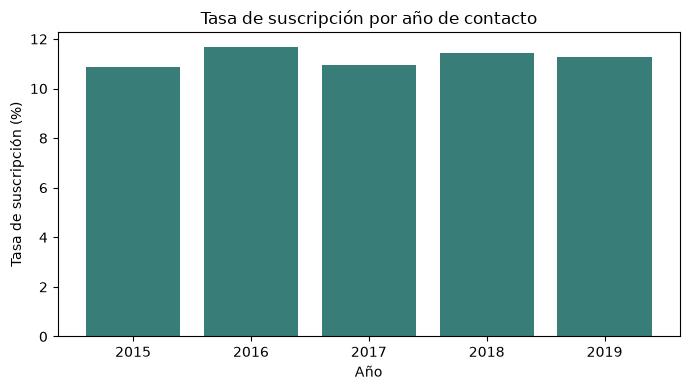

In [34]:
plt.figure(figsize=(7, 4))
plt.bar(yearly_summary.index.astype(int).astype(str), yearly_summary["rate"] * 100, color="#397d78")
plt.title("Tasa de suscripción por año de contacto")
plt.xlabel("Año")
plt.ylabel("Tasa de suscripción (%)")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "13_tasa_por_anio_contacto.png"))
plt.show()


## 14. Explorar variables de cliente

Se comparan las visitas web según el número de hijos y adolescentes en el hogar, y la tasa de suscripción según el año de alta disponible en las hojas del Excel. Son comparaciones descriptivas.


In [35]:
visits_by_children = combined.groupby(["Kidhome", "Teenhome"])["NumWebVisitsMonth"].agg(
    ["count", "mean", "median"]
)
visits_by_children


                  count       mean  median
Kidhome Teenhome                          
0       0          4754  16.529659    17.0
        1          4716  16.724979    17.0
        2          4740  16.797890    17.0
1       0          4788  16.466165    16.0
        1          4791  16.740973    17.0
        2          4795  16.383733    16.0
2       0          4803  16.706433    17.0
        1          4863  16.626362    17.0
        2          4750  16.332000    16.0

In [36]:
subscription_by_sheet_year = combined.groupby("customer_sheet_year")["y"].agg(
    ["count", lambda values: (values == "yes").sum()]
)
subscription_by_sheet_year.columns = ["contacts", "subscriptions"]
subscription_by_sheet_year["rate"] = (
    subscription_by_sheet_year["subscriptions"] / subscription_by_sheet_year["contacts"]
)
subscription_by_sheet_year


                     contacts  subscriptions      rate
customer_sheet_year                                   
2012                    20018            918  0.045859
2013                     8918            690  0.077372
2014                    14064           3236  0.230091

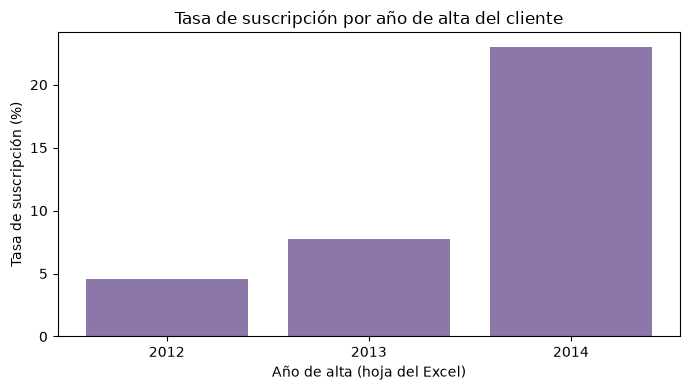

In [37]:
plt.figure(figsize=(7, 4))
plt.bar(subscription_by_sheet_year.index.astype(str),
        subscription_by_sheet_year["rate"] * 100, color="#8c78a8")
plt.title("Tasa de suscripción por año de alta del cliente")
plt.xlabel("Año de alta (hoja del Excel)")
plt.ylabel("Tasa de suscripción (%)")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "14_tasa_por_anio_alta.png"))
plt.show()


## 15. Guardar los datos preparados

Se guardan campañas limpias, fichas combinadas y la tabla final cruzada. Los gráficos se guardan en `outputs/graficos/`.


In [38]:
campaigns.to_csv(os.path.join(PROCESSED, "bank-additional-limpio.csv"), index=False)
customers.to_csv(os.path.join(PROCESSED, "customer-details-combinado.csv"), index=False)
combined.to_csv(os.path.join(PROCESSED, "campanas-clientes-combinado.csv"), index=False)

print("Tablas guardadas en:", PROCESSED)
print("Gráficos guardados en:", CHARTS)


Tablas guardadas en: C:\Users\TPV SYSTEM\Desktop\EDA CURSO\PYTHON FOR DATA\data\processed
Gráficos guardados en: C:\Users\TPV SYSTEM\Desktop\EDA CURSO\PYTHON FOR DATA\outputs\graficos


## 16. Conclusiones

El análisis recoge 43.000 contactos telefónicos y 4.844 suscripciones. La tasa general es del 11,27 %; por tanto, la mayoría de las personas contactadas no contrató el depósito. Este resultado sirve como referencia global para comparar los distintos grupos.
- Canal de contacto. La tasa de suscripción fue del 14,74 % en cellular y del 5,16 % en telephone. En estos datos, el canal celular aparece asociado a una proporción mayor de suscripciones. El análisis no permite afirmar que el canal sea la causa: podrían influir otras diferencias entre las personas contactadas o las campañas.
- Resultado de campañas anteriores. Entre quienes tenían un resultado anterior SUCCESS, la tasa fue del 65,32 % (938 suscripciones de 1.436 contactos). En FAILURE fue del 14,23 %, y en NONEXISTENT, del 8,82 %. El resultado previo parece útil para describir grupos con respuestas distintas, aunque el grupo SUCCESS es mucho más pequeño y los datos no demuestran que ese antecedente cause la nueva suscripción.
- Duración de las llamadas. La mediana fue de 449 segundos para las llamadas que terminaron en suscripción y de 163 segundos para las que no. La diferencia es clara en estos registros, pero la duración se conoce al terminar la llamada. Por eso sirve para describir las interacciones ya realizadas, no para decidir de antemano a quién llamar.
- Distribución de duración y valores alejados. La mitad central de las llamadas duró entre 102 y 319 segundos. La distribución tiene una cola larga: 3.072 llamadas superan el límite superior de los bigotes del diagrama de caja (644,5 segundos). Estos casos son llamadas especialmente largas según una regla estadística; no necesariamente son errores y no se han eliminado.
- Edad. La mediana es 38 años y la mitad central de las edades va de 32 a 47 años. El diagrama señala 441 edades fuera de sus bigotes, que conviene interpretar como observaciones alejadas del grupo central y no como errores automáticos. Faltan 5.120 edades, de modo que el resumen se calcula con las 37.880 disponibles.
- Ingresos. La mitad central de los ingresos va aproximadamente de 49.610 a 136.745, con una mediana cercana a 93.051. Aunque los valores cubren un rango amplio, ninguno queda fuera de los bigotes del diagrama según la regla usada. Los ingresos medios de quienes suscribieron y quienes no fueron parecidos (aproximadamente 92.584 y 93.325, respectivamente); en esta exploración no aparece una diferencia grande entre esos grupos.
- Variables económicas. emp.var.rate y euribor3m presentan una correlación positiva alta (aproximadamente 0,97); euribor3m y nr.employed también (aproximadamente 0,95). Esto indica que esas variables se movieron de forma parecida dentro de estos registros. Una correlación no demuestra que una variable provoque cambios en otra. Además, faltan 9.256 valores de euribor3m, por lo que las correlaciones que incluyen esa columna se calculan con los registros donde ambas variables tienen dato.
- Momento del contacto. La tasa mensual varía entre 10,25 % en septiembre y 12,36 % en octubre. Por año, oscila entre 10,87 % en 2015 y 11,68 % en 2016, sin una subida o bajada continua hasta 2019. Son variaciones moderadas y descriptivas, no evidencia de que el mes o el año causen una mayor contratación. Se convirtieron las fechas con mes escrito en español; 248 fechas ausentes no entran en estos resúmenes.
- Características de los clientes. Las visitas web mensuales medias son prácticamente iguales para yes y no (aproximadamente 16,60 en ambos grupos). Al cruzarlas con el número de niños y adolescentes en el hogar, las medias también quedan en torno a 16–17 visitas; no destaca una diferencia marcada. La tasa por año de alta en la hoja de clientes es 4,59 % para 2012, 7,74 % para 2013 y 23,01 % para 2014. Aunque la diferencia de 2014 destaca, estas cohortes no tienen el mismo tamaño (20.018, 8.918 y 14.064 contactos), así que conviene presentarla como un patrón que requeriría más investigación, no como explicación definitiva.
En conjunto, el resultado anterior y el canal muestran diferencias descriptivas más visibles que los ingresos o las visitas web. Los gráficos de distribución ayudan a localizar asimetrías y observaciones alejadas para revisarlas con contexto. El análisis es exploratorio: no prueba causas ni permite asegurar que los mismos patrones se repitan en otras campañas. Se conservaron los valores ausentes sin imputarlos, y cada cálculo usa los datos disponibles para las variables que compara.
